## Mass calibration and IM window determination

### 1. Mass calibration

For mass calibration, the observed m/z at the apex of each XIC is recorded. The monoisotopic precursor XIC is used for MS1-level mass calibration, while the best product ion XIC is used for MS2-level mass calibration.

The mass calibration data for each run is stored in the `intermediate/mass_calibration` folder in the output directory.

In [1]:
import numpy as np
import pandas as pd

mass_cali_data = pd.read_csv(r"..\tests\H6_3_S1-D10_1_660_mass_cal.csv")
mass_cali_data.head(5)

,theoretical_mz_ms1,theoretical_mz_ms2,observed_mz_ms1,observed_mz_ms2,mass_delta_ms1,mass_delta_ms2,experimental_rt,query_mz_ms1,query_mz_ms2
0,591.606384,813.853149,591.611633,813.857361,0.005249,0.004211,4.417510,591.610945,813.858505
1,673.302551,746.342773,673.308777,746.348938,0.006226,0.006165,4.486762,673.307959,746.347696
2,669.804626,819.420654,669.809326,819.426453,0.004700,0.005798,4.502742,669.809996,819.426045
3,685.333984,506.259583,685.339478,506.262848,0.005493,0.003265,4.554237,685.339525,506.262849
4,580.288757,466.233215,580.291382,466.235474,0.002625,0.002258,4.561339,580.293209,466.236188


In [2]:
from jumplion.calibration import split_into_rt_bins

# sort by RT
mass_cali_data = mass_cali_data.sort_values(by="experimental_rt")

# setup for mass calibration bins
(mass_cal_bins, 
 mass_cal_split, 
 mass_cal_center) = split_into_rt_bins(mass_cali_data['experimental_rt'].to_numpy(), 
                                       max_num_bins=1, # maximum number of bins
                                       min_points_per_bin=500, # minimum number of data points needed for a bin
                                       tolerance=1e-6)

print(mass_cal_bins)
print(mass_cal_split)
print(mass_cal_center)

1
[np.float64(4.41751), np.float64(41.992203)]
[np.float64(23.2048565)]


In [3]:
from jumplion.calibration import build_mass_cali_model, predicted_mz_parallel, mass_calibration_plot

def mass_calibration(mass_cali_data, level, mass_cal_center, mass_cal_bins):
    assert level in ['ms1', 'ms2']

    theo_col = f'theoretical_mz_{level}'
    delta_col = f'mass_delta_{level}'
    obs_col = f'observed_mz_{level}'
    query_col = f'query_mz_{level}'

    # Step 1: Check mass error before correction
    theo = mass_cali_data[theo_col].to_numpy()
    b_r = mass_cali_data[delta_col].to_numpy() / theo
    mean = np.mean(b_r)
    sd = np.std(b_r)
    print(f"Mean and SD of {level.upper()} mass error before calibration: {np.round(mean * 1e6, 2)} and {np.round(sd * 1e6, 2)} ppm")
    acc_no_cal = np.round(max(abs(mean+3*sd), abs(mean-3*sd)) * 1e6 + 5) / 1e6
    
    # Step 2: Build calibration model
    correction = build_mass_cali_model(
        theoretical_mzs = mass_cali_data[theo_col].to_numpy(),
        delta_mzs = mass_cali_data[delta_col].to_numpy(),
        rts = mass_cali_data['experimental_rt'].to_numpy(),
        RTBinCenter = mass_cal_center,
        nRTBins = mass_cal_bins
    )

    # Step 3: Recalculate query m/z
    query_mz = predicted_mz_parallel(
        correction,
        mass_cali_data[theo_col].to_numpy().reshape(-1, 1),
        mass_cali_data['experimental_rt'].to_numpy(),
        mass_cal_center,
        mass_cal_bins
    ).reshape(-1)
    mass_cali_data[query_col] = query_mz

    # Step 4: Compute mass error
    observed = mass_cali_data[obs_col].to_numpy()
    b_r = (observed - query_mz) / theo
    mean = np.mean(b_r)
    sd = np.std(b_r)
    print(f"Mean and SD of {level.upper()} mass error after calibration: {np.round(mean * 1e6, 2)} and {np.round(sd * 1e6, 2)} ppm")
    acc = np.round(max(abs(mean+3*sd), abs(mean-3*sd)) * 1e6 + 5) / 1e6
    print(f'{level.upper()} mass accuracy set to {acc*1e6} ppm')

    if acc_no_cal < acc:
        print(f"No {level.upper()} mass correction required")
        print(f'{level.upper()} mass accuracy reset to {acc_no_cal*1e6} ppm')
    
    return mass_cali_data

Mean and SD of MS1 mass error before calibration: 8.43 and 1.9 ppm
Mean and SD of MS1 mass error after calibration: -0.0 and 1.8 ppm
MS1 mass accuracy set to 10.0 ppm
Mean and SD of MS2 mass error before calibration: 6.5 and 1.58 ppm
Mean and SD of MS2 mass error after calibration: 0.0 and 1.57 ppm
MS2 mass accuracy set to 10.0 ppm


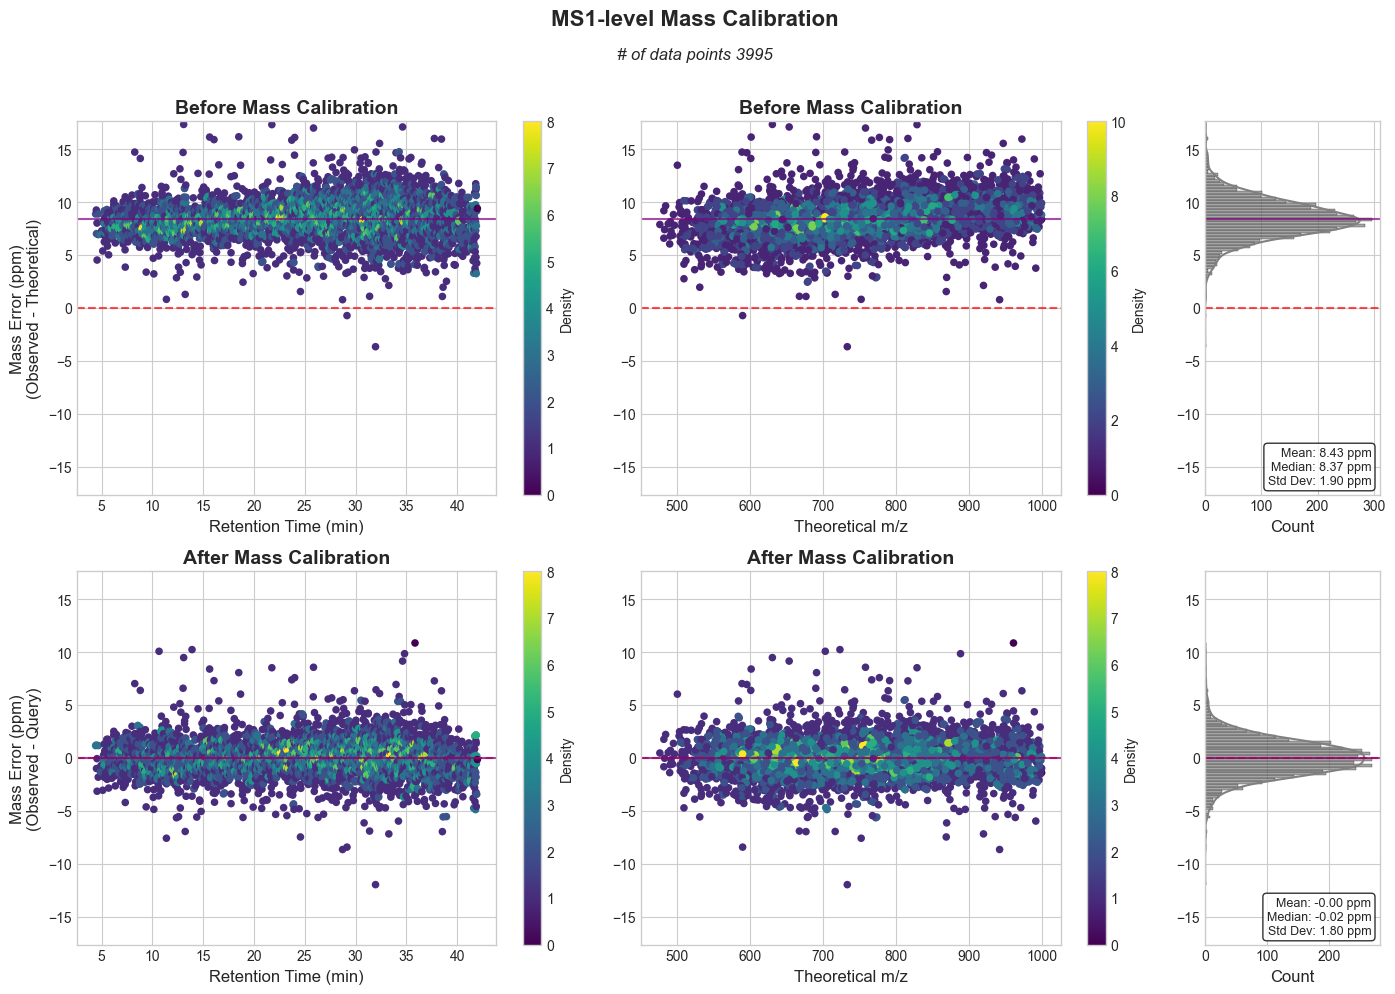

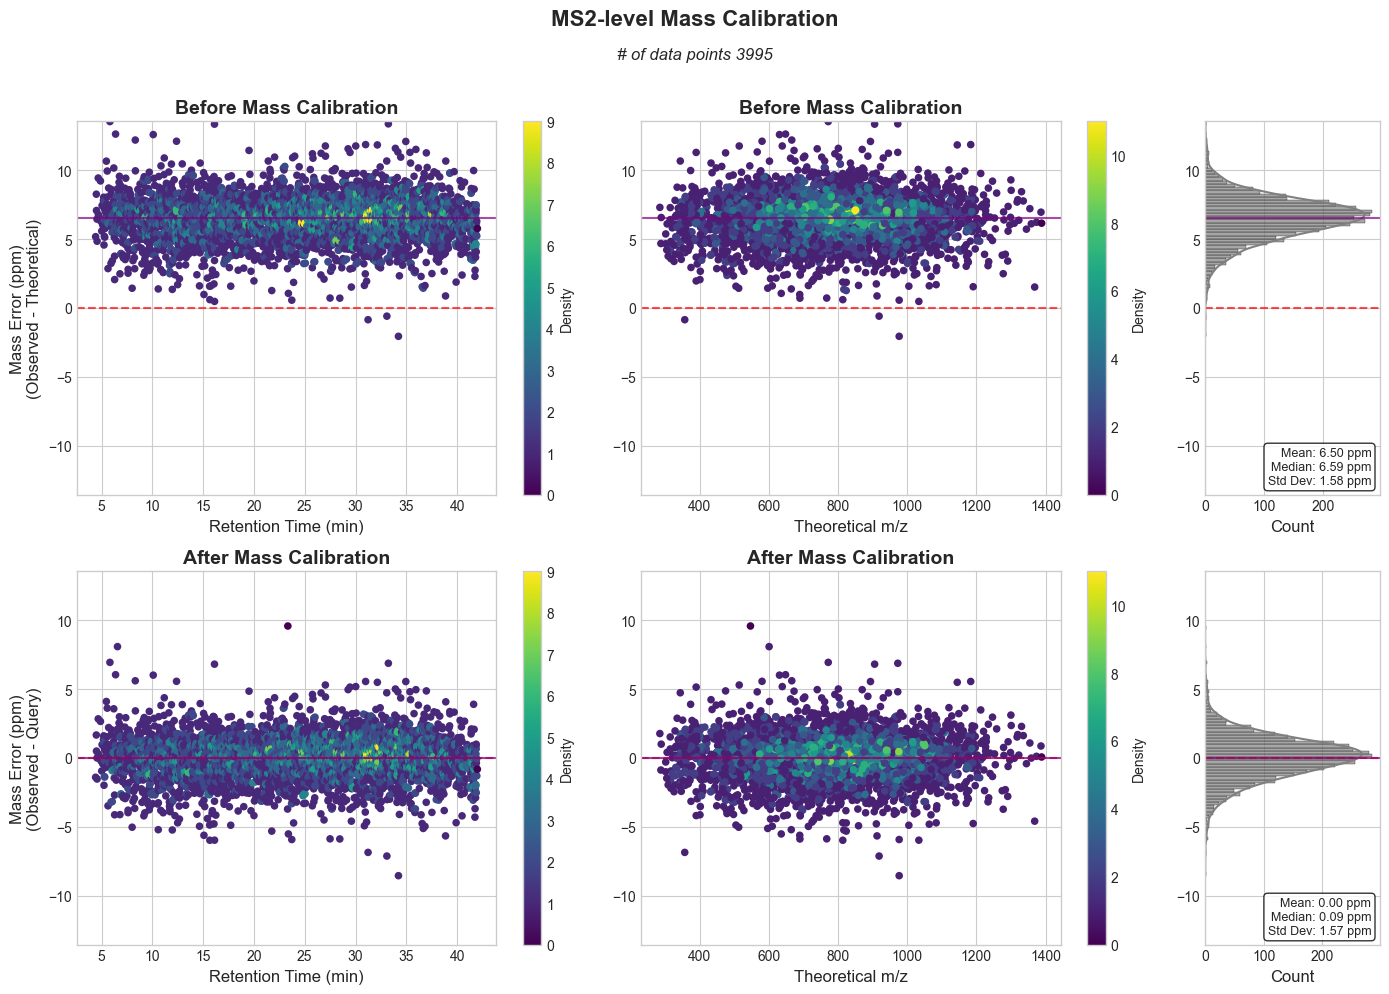

In [4]:
mass_cali_data = mass_calibration(mass_cali_data, 'ms1', mass_cal_center, mass_cal_bins)
mass_cali_data = mass_calibration(mass_cali_data, 'ms2', mass_cal_center, mass_cal_bins)

mass_calibration_plot(mass_cali_data, 'ms1', run_name='', save_plot=False)
mass_calibration_plot(mass_cali_data, 'ms2', run_name='', save_plot=False)

### 2. Determine IM window


In [5]:
im_cali_data = pd.read_csv(r"..\tests\H6_3_S1-D10_1_660_im_error.csv") 
im_cali_data = im_cali_data.sort_values(by="query_im")
print(f"{len(im_cali_data)} IM values are used for IM window determination") 
im_cali_data.head(6)

3994 IM values are used for IM window determination


,theoretical_mz,query_im,im_delta
0,567.299622,0.851250,-0.006167
1,544.608093,0.851467,-0.005076
2,563.904419,0.851587,-0.005499
3,509.935333,0.852355,-0.004237
4,562.876526,0.852500,-0.006622
6,494.893127,0.852500,-0.007220


Mean and SD of ion mobility error: -0.0008 and 0.00174
Final ion mobility window for XIC extraction: 0.007


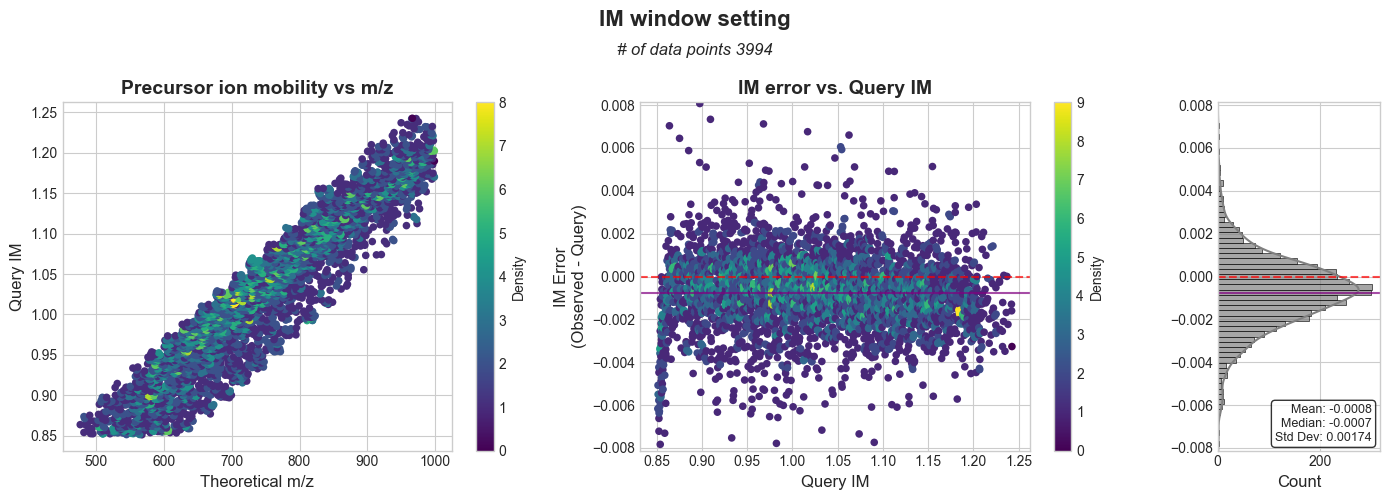

In [7]:
from jumplion.calibration import im_error_plot

# calibration       
mean = im_cali_data['im_delta'].mean()
sd = im_cali_data['im_delta'].std()
print(f"Mean and SD of ion mobility error: {np.round(mean, 4)} and {np.round(sd, 5)}")
im_boundary = max(abs(mean+3*sd), abs(mean-3*sd)) * 1.25
IM_window = np.round(im_boundary, 3)
print(f"Final ion mobility window for XIC extraction: {IM_window}")
im_error_plot(im_cali_data, run_name="", save_plot=False)